# Phase 1: Data Inspection & Validation Notebook
## Project: Workforce Attrition Patterns and Risk Hotspot Analysis
**Scope:** Phase 1 – Dataset Inspection, Structural Integrity & Validation Audits

> **DISCLAIMER:** The dataset provenance is UNVERIFIED. This data is analyzed as a public/synthetic HR dataset. Findings must not be described as real Palo Alto Networks employment records or personnel data. No data transformations or cleaning are performed in this inspection phase.

In [1]:
import sys
from pathlib import Path

# Ensure project src is in python path
project_root = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(project_root / 'src'))

import pandas as pd
from IPython.display import display, Image

from workforce_intel.config import (
    RAW_DATA_FILE, EXPECTED_COLUMNS, NOMINAL_COLUMNS,
    ORDINAL_COLUMNS_DOCUMENTED_RANGES, PHASE1_FIGURES_DIR
)
from workforce_intel.io import load_raw
from workforce_intel.validation import (
    structure_report, missing_report, duplicate_report,
    categorical_audit, range_audit, target_audit,
    consistency_checks, zero_audit, outlier_report,
    collinearity_report, group_size_report, constant_column_check
)

print('Libraries and validation modules imported successfully.')

Libraries and validation modules imported successfully.


## 1. Safe Dataset Loading & Schema Structure
Load the raw dataset using `load_raw()` and verify structural conformity against `EXPECTED_COLUMNS`.

In [2]:
df, delimiter = load_raw(RAW_DATA_FILE)
print(f'Detected Delimiter: {delimiter}')
struct = structure_report(df)
print(f"Dimensions: {struct['n_rows']} rows x {struct['n_cols']} columns")
print(f"Memory: {struct['memory_mb']} MB")
print(f"Contract Violated: {struct['contract_violated']}")
print(f"Column order matches expected: {struct['order_matches_expected']}")
display(struct['details_table'].head(10))

Detected Delimiter: ,
Dimensions: 1470 rows x 31 columns
Memory: 0.85 MB
Contract Violated: False
Column order matches expected: True


,column,dtype,is_numeric,is_string,non_null_count,null_count
0,Age,int64,True,False,1470,0
1,Attrition,int64,True,False,1470,0
2,BusinessTravel,str,False,True,1470,0
3,DailyRate,int64,True,False,1470,0
4,Department,str,False,True,1470,0
5,DistanceFromHome,int64,True,False,1470,0
6,Education,int64,True,False,1470,0
7,EducationField,str,False,True,1470,0
8,EnvironmentSatisfaction,int64,True,False,1470,0
9,Gender,str,False,True,1470,0


## 2. Missing Values, Sentinels & Duplicates
Audit missing cells, empty/whitespace strings, and sentinel values (`?`, `NA`, `-1`, `999`).

In [3]:
missing_df = missing_report(df)
print('Total NaN cells across dataset:', missing_df['nan_count'].sum())
print('Total empty string cells:', missing_df['empty_string_count'].sum())
print('Total sentinel tokens:', missing_df['string_sentinel_count'].sum() + missing_df['numeric_sentinel_count'].sum())

dup_report = duplicate_report(df)
print('Full-row duplicates:', dup_report['full_row_duplicates'])
print('Demographic key subset duplicates:', dup_report['key_subset_duplicates'])

Total NaN cells across dataset: 0
Total empty string cells: 0
Total sentinel tokens: 1
Full-row duplicates: 0
Demographic key subset duplicates: 35


## 3. Target Variable Audit (`Attrition`)
Verify binary compliance {0, 1}, class balance, and the Wilson 95% Confidence Interval.

Target column: Attrition
Distinct values: [0, 1]
Class 0 (Stayed): 1233 (83.88%)
Class 1 (Left):   237 (16.12%)
Imbalance Ratio: 5.2:1
Wilson 95% Score CI for Attrition=1: [14.33%, 18.09%]


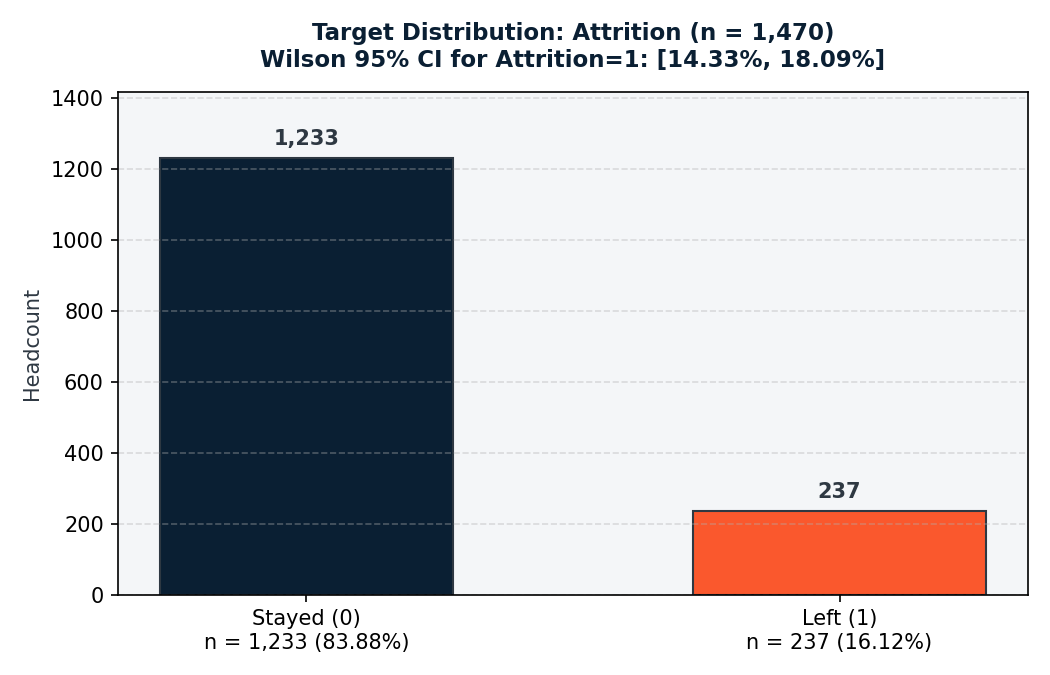

In [4]:
target = target_audit(df)
print('Target column:', target['target_column'])
print('Distinct values:', target['distinct_values'])
print(f"Class 0 (Stayed): {target['count_attrition_0']} ({target['rate_attrition_0_pct']}%)")
print(f"Class 1 (Left):   {target['count_attrition_1']} ({target['rate_attrition_1_pct']}%)")
print(f"Imbalance Ratio: {target['imbalance_ratio_stayed_to_left']}:1")
print(f"Wilson 95% Score CI for Attrition=1: [{target['wilson_95_ci_lower_pct']}%, {target['wilson_95_ci_upper_pct']}%]")
display(Image(filename=str(PHASE1_FIGURES_DIR / 'target_distribution.png')))

## 4. Domain & Temporal Consistency Checks (C1 – C9)
Evaluate tenure progression rules, hierarchy structures, and compensation rates coherence.

In [5]:
consistency = consistency_checks(df)
print('C1 (YearsAtCompany <= TotalWorkingYears) violations:', consistency['C1']['violation_count'])
print('C2 (YearsInCurrentRole <= YearsAtCompany) violations:', consistency['C2']['violation_count'])
print('C3 (YearsSinceLastPromotion <= YearsAtCompany) violations:', consistency['C3']['violation_count'])
print('C4 (YearsWithCurrManager <= YearsAtCompany) violations:', consistency['C4']['violation_count'])
print('C5 Hard (TotalWorkingYears <= Age - 14) violations:', consistency['C5_hard']['violation_count'])
print('C5 Soft (TotalWorkingYears <= Age - 18) violations:', consistency['C5_soft']['violation_count'])
print('C6 (NumCompaniesWorked == 0 & TotalWorkingYears > YearsAtCompany) ambiguities:', consistency['C6']['violation_count'])
print(f"C7 Department x JobRole populated cells: {consistency['C7']['populated_cells']} of {consistency['C7']['total_cells']}")
display(consistency['C7']['crosstab_table'])

C1 (YearsAtCompany <= TotalWorkingYears) violations:

 0
C2 (YearsInCurrentRole <= YearsAtCompany) violations: 0
C3 (YearsSinceLastPromotion <= YearsAtCompany) violations: 0
C4 (YearsWithCurrManager <= YearsAtCompany) violations: 0
C5 Hard (TotalWorkingYears <= Age - 14) violations: 0
C5 Soft (TotalWorkingYears <= Age - 18) violations: 0
C6 (NumCompaniesWorked == 0 & TotalWorkingYears > YearsAtCompany) ambiguities: 197
C7 Department x JobRole populated cells: 11 of 27


JobRole,Healthcare Representative,Human Resources,Laboratory Technician,Manager,Manufacturing Director,Research Director,Research Scientist,Sales Executive,Sales Representative
Department,,,,,,,,,
Human Resources,0,52,0,11,0,0,0,0,0
Research & Development,131,0,259,54,145,80,292,0,0
Sales,0,0,0,37,0,0,0,326,83


## 5. Zero-Value Audit & Outliers
Inspect zero counts and detect 1.5x / 3.0x IQR outliers.

,column,zero_count,zero_pct,candidate_classification
7,StockOptionLevel,631,42.93,legitimate zero (no stock options granted)
13,YearsSinceLastPromotion,581,39.52,legitimate zero (promoted within current year)
14,YearsWithCurrManager,263,17.89,legitimate zero (new manager assignment)
12,YearsInCurrentRole,244,16.60,legitimate zero (recently transferred / promoted)
9,NumCompaniesWorked,197,13.40,ambiguous (could indicate 0 prior employers or...
10,TrainingTimesLastYear,54,3.67,legitimate zero (no formal training attended)
11,YearsAtCompany,44,2.99,legitimate zero (new hire in first year)
15,TotalWorkingYears,11,0.75,legitimate zero (entry level / first professio...


,column,q1,median,q3,iqr,outliers_count_1_5x,outliers_pct_1_5x,skewness
5,PerformanceRating,3.0,3.0,3.0,0.0,226,15.37,1.922
7,StockOptionLevel,0.0,1.0,1.0,1.0,85,5.78,0.969
9,NumCompaniesWorked,1.0,2.0,4.0,3.0,52,3.54,1.026
10,TrainingTimesLastYear,2.0,3.0,3.0,1.0,238,16.19,0.553
11,YearsAtCompany,3.0,5.0,9.0,6.0,104,7.07,1.765
12,YearsInCurrentRole,2.0,3.0,7.0,5.0,21,1.43,0.917
13,YearsSinceLastPromotion,0.0,1.0,3.0,3.0,107,7.28,1.984
14,YearsWithCurrManager,2.0,3.0,7.0,5.0,14,0.95,0.833
15,TotalWorkingYears,6.0,10.0,15.0,9.0,63,4.29,1.117
20,MonthlyIncome,2911.0,4919.0,8379.0,5468.0,114,7.76,1.370


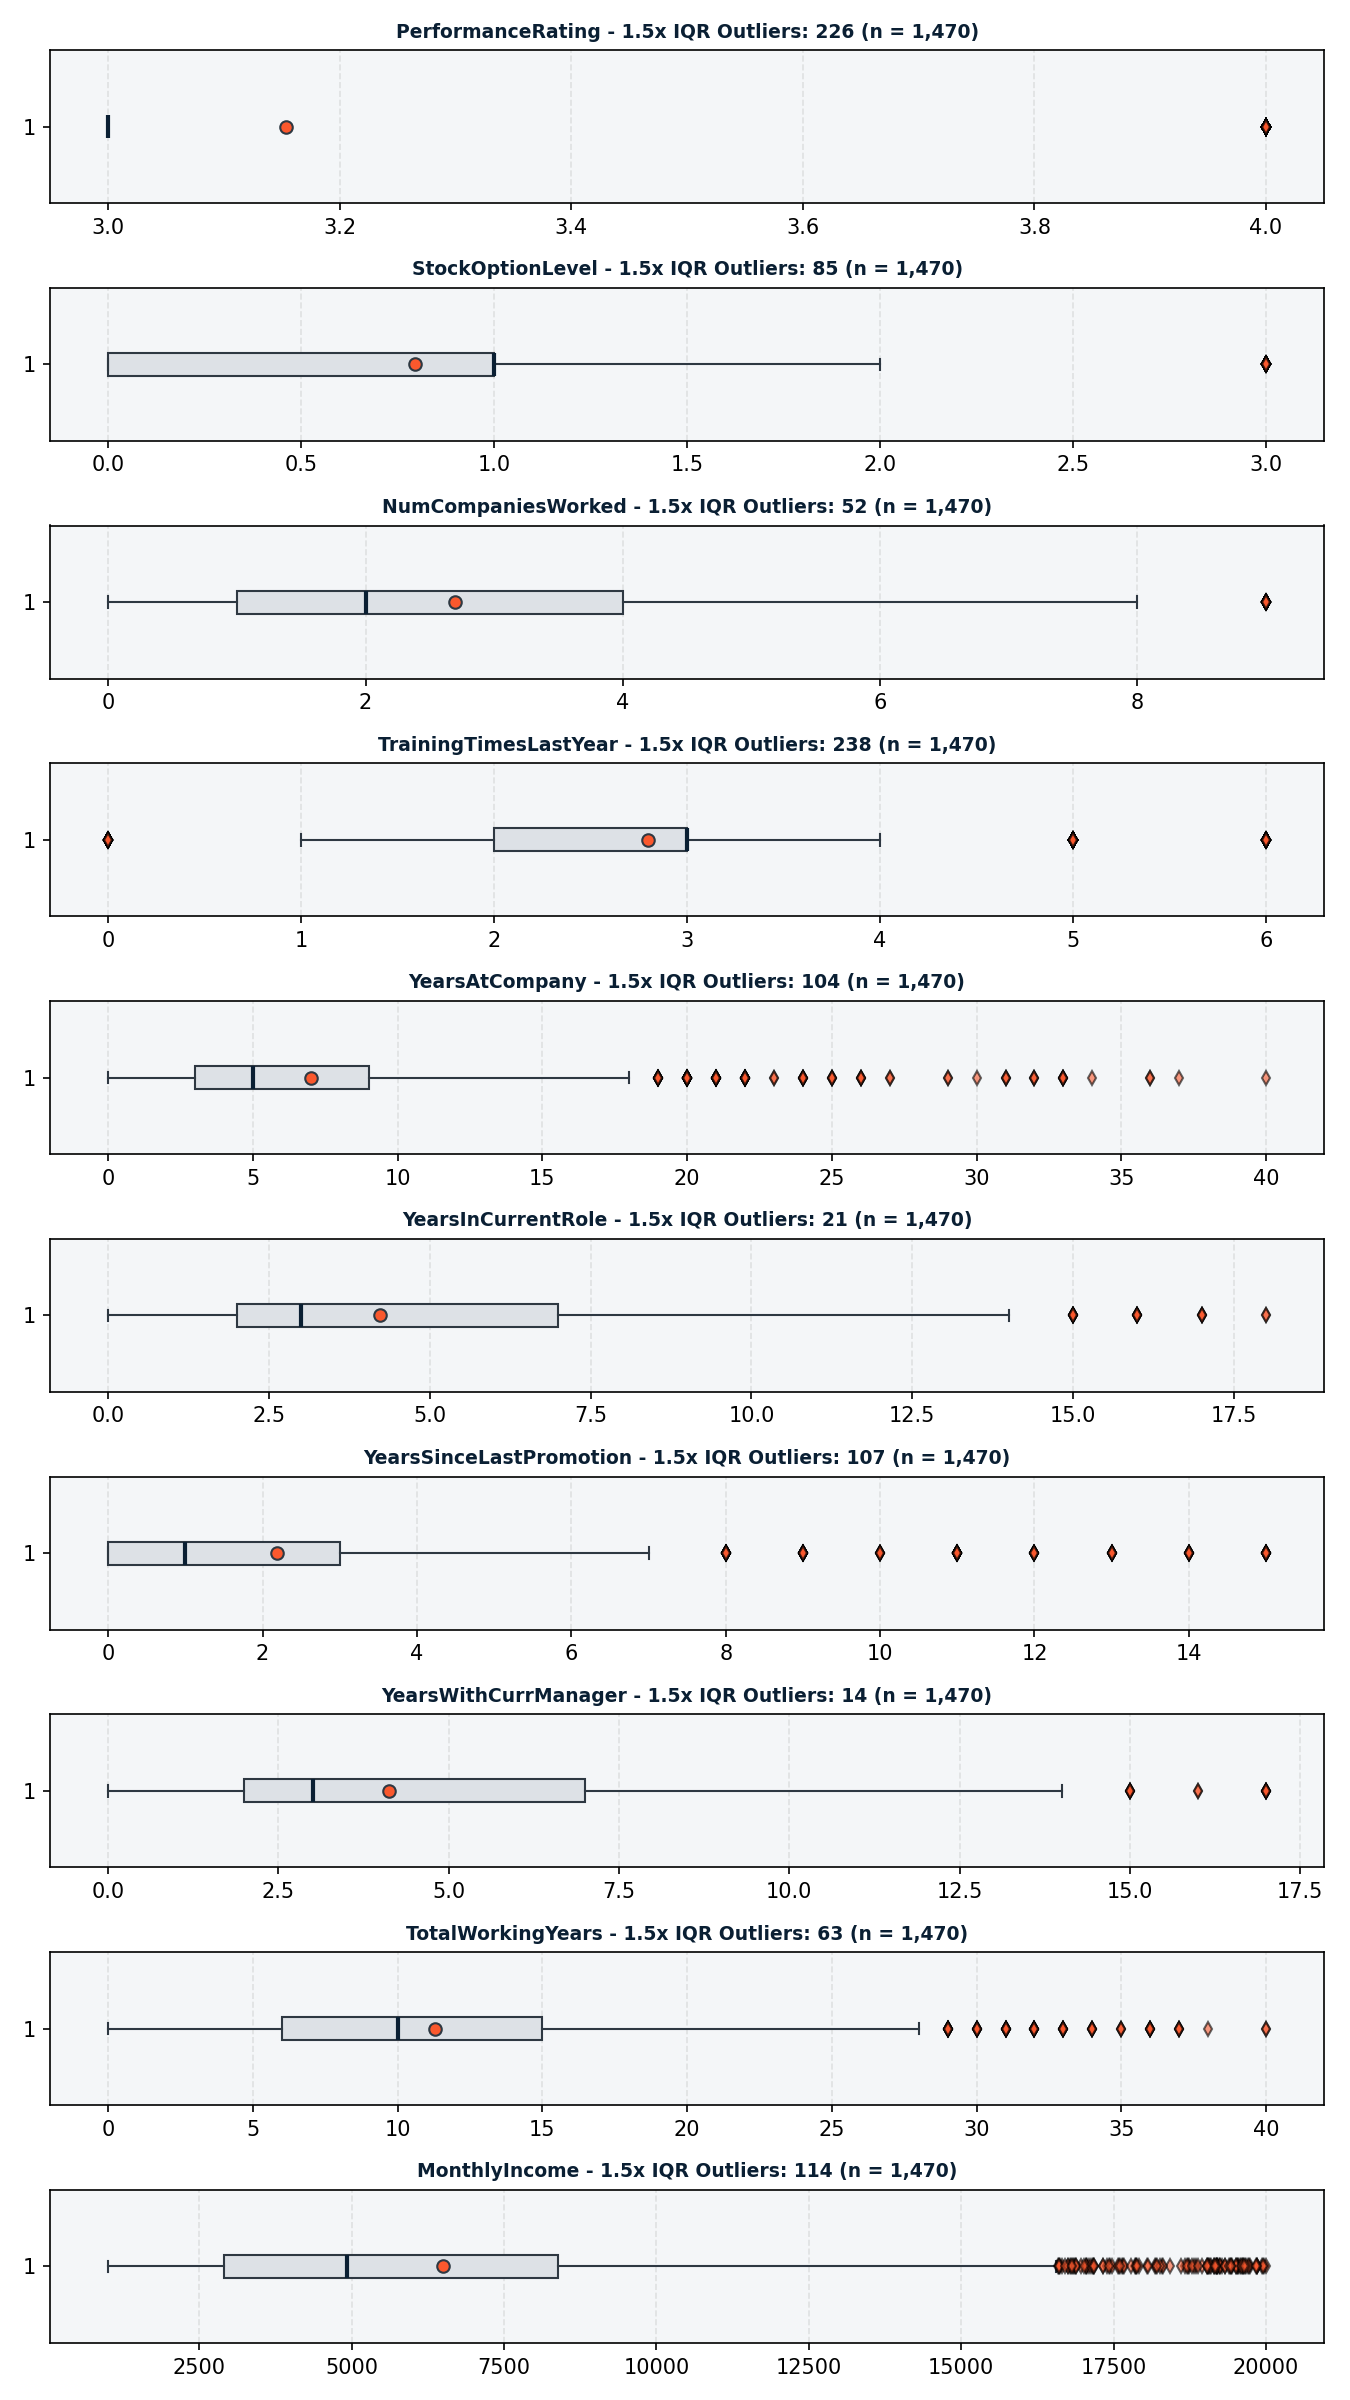

In [6]:
zero_df = zero_audit(df)
display(zero_df[zero_df['zero_count'] > 0].sort_values(by='zero_count', ascending=False))

outliers_df = outlier_report(df)
display(outliers_df[outliers_df['outliers_count_1_5x'] > 0][['column', 'q1', 'median', 'q3', 'iqr', 'outliers_count_1_5x', 'outliers_pct_1_5x', 'skewness']])
display(Image(filename=str(PHASE1_FIGURES_DIR / 'boxplots_outliers.png')))

## 6. Ordinal Ranges, Collinearity & Figures
Audit scale adherence, high correlation pairs (|rho| >= 0.7), and visualize Spearman matrix.

Restricted range columns: ['PerformanceRating']
High collinearity pairs (|rho| >= 0.7):


,feature_1,feature_2,spearman_rho,abs_rho
0,JobLevel,MonthlyIncome,0.9204,0.9204
1,YearsAtCompany,YearsInCurrentRole,0.8540,0.8540
2,YearsAtCompany,YearsWithCurrManager,0.8428,0.8428
3,JobLevel,TotalWorkingYears,0.7347,0.7347
4,YearsInCurrentRole,YearsWithCurrManager,0.7248,0.7248
5,TotalWorkingYears,MonthlyIncome,0.7100,0.7100


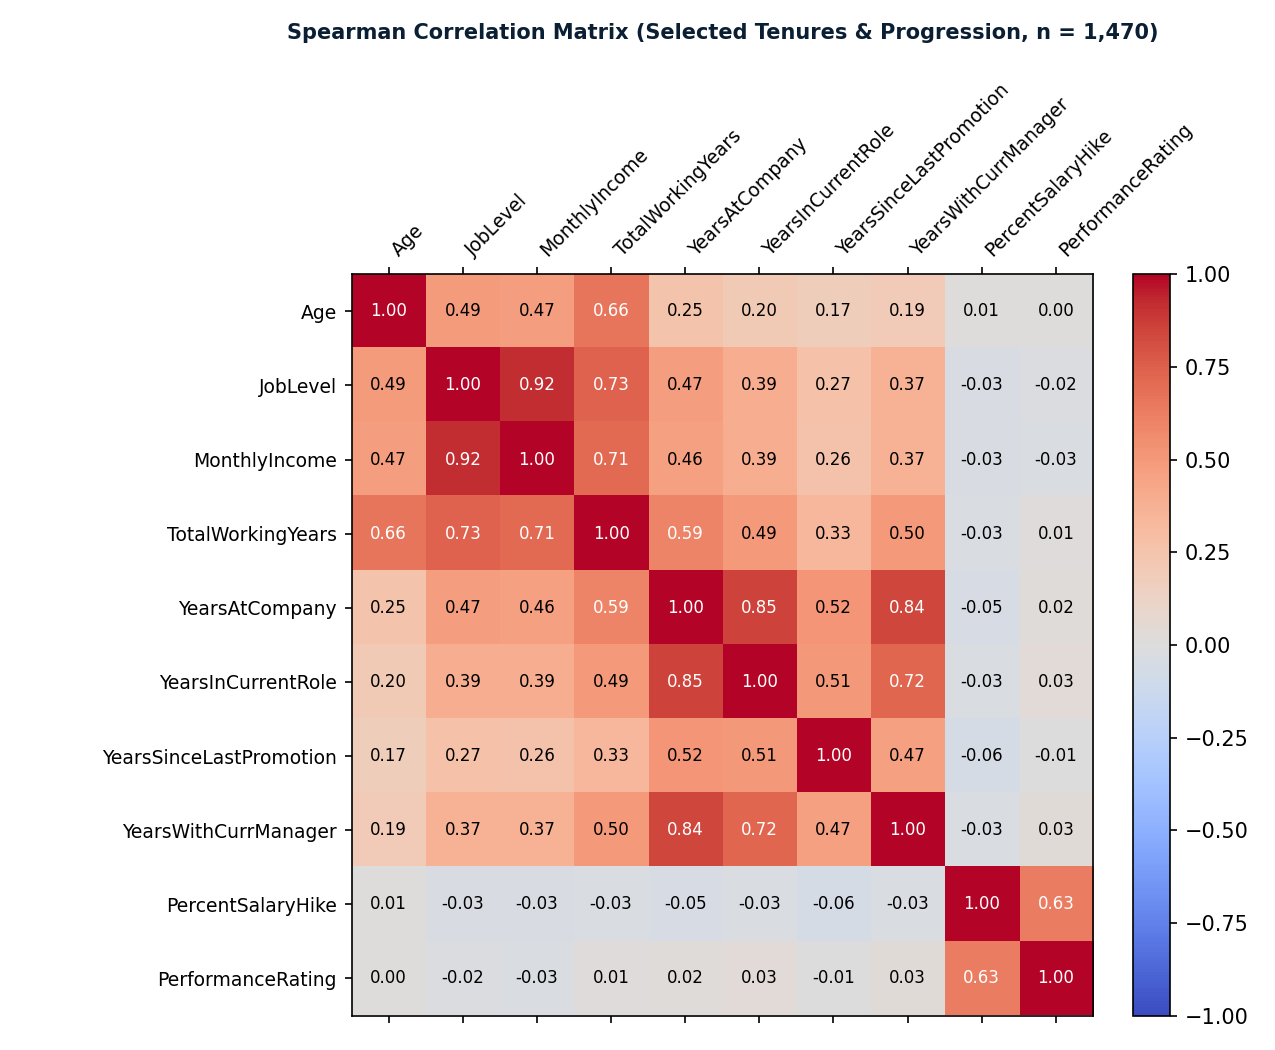

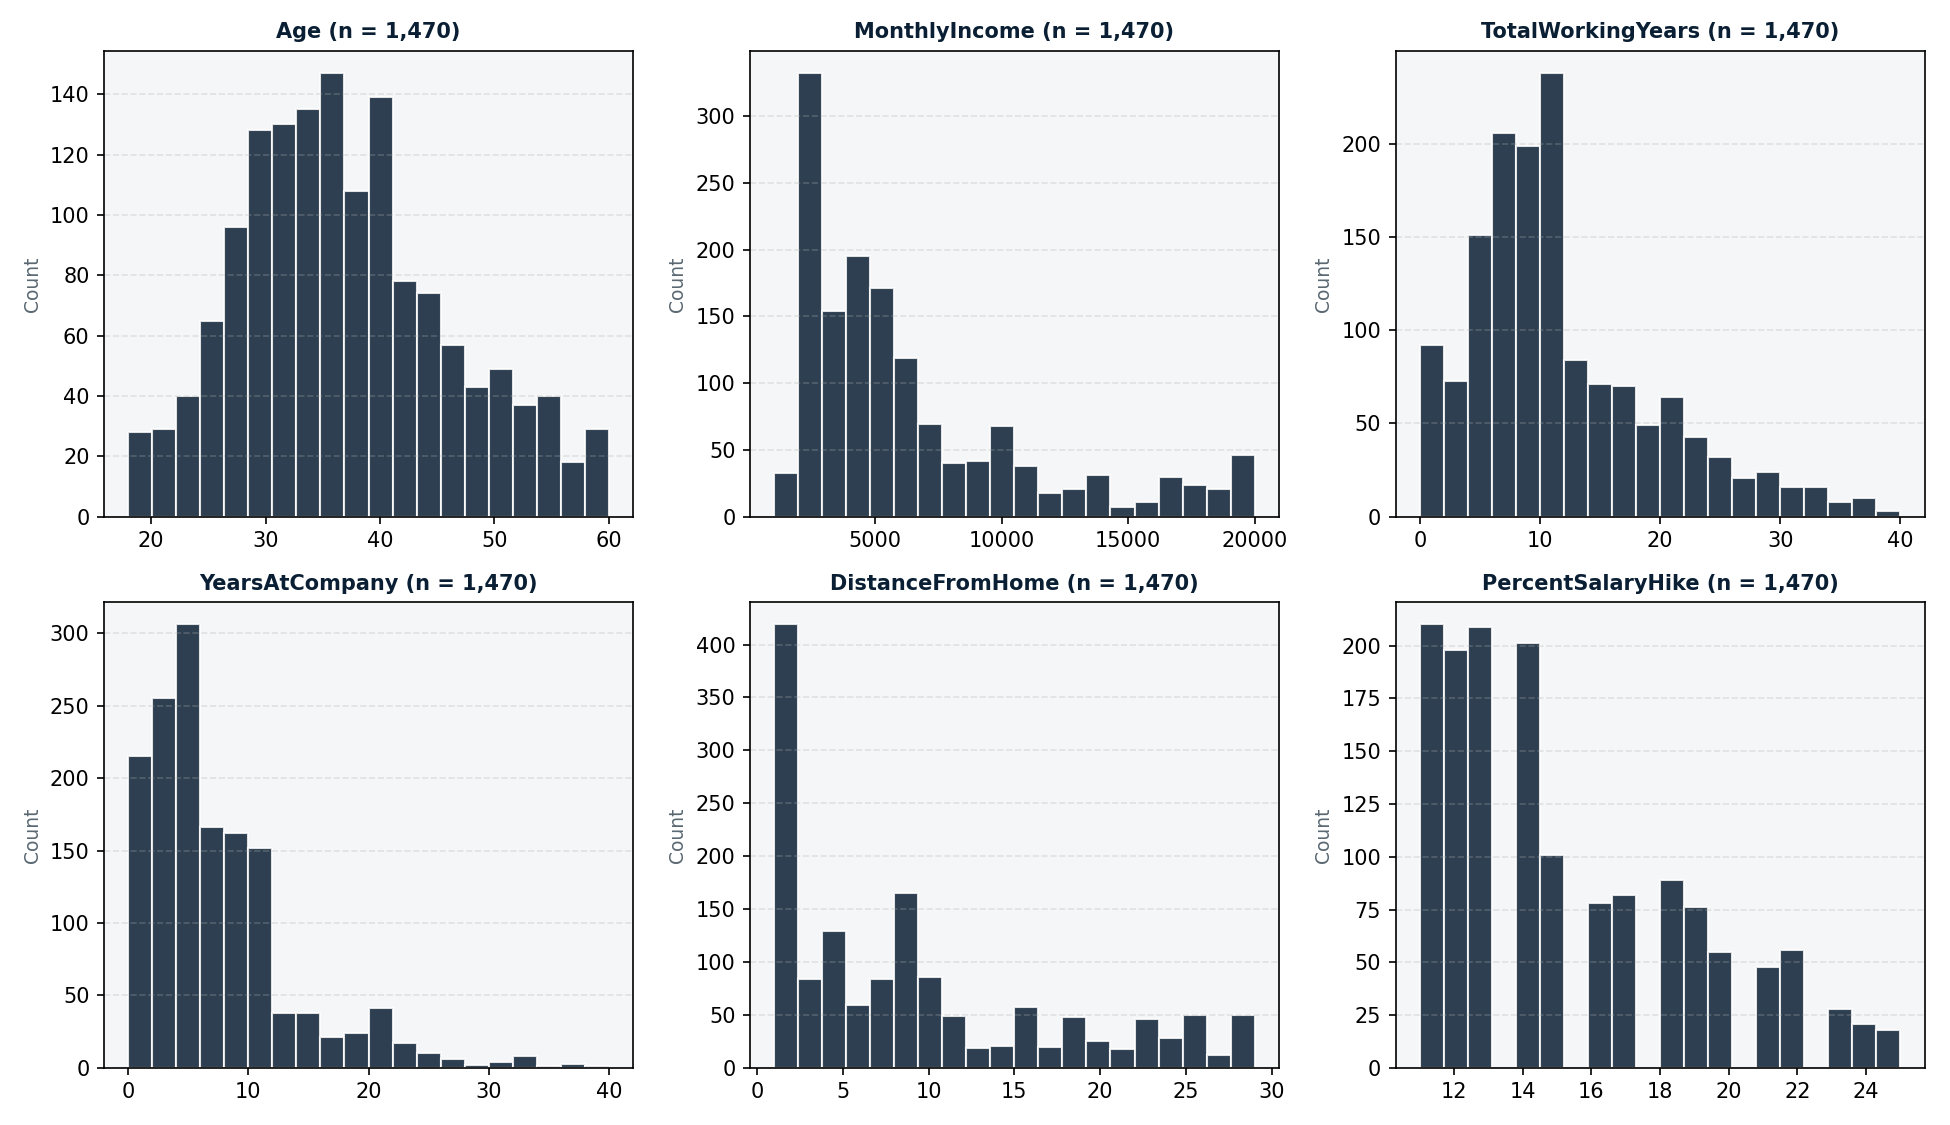

In [7]:
range_df = range_audit(df)
print('Restricted range columns:', range_df[range_df['is_restricted_range']]['column'].tolist())

collin = collinearity_report(df)
print('High collinearity pairs (|rho| >= 0.7):')
display(collin['high_correlation_pairs'])
display(Image(filename=str(PHASE1_FIGURES_DIR / 'spearman_heatmap.png')))
display(Image(filename=str(PHASE1_FIGURES_DIR / 'numeric_distributions_grid.png')))